In [30]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Fetching Data

In [31]:
os.chdir('C:\\Users\\Mohit Chaudhary\\OneDrive\\Desktop\\Github Projects\\power bi\\HR Dataset')

In [32]:
emp_df=pd.read_csv('HR_Analytics.csv')

In [33]:
emp_df.head()

,EmpID,Age,AgeGroup,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,RM297,18,18-25,Yes,Travel_Rarely,230,Research & Development,3,3,Life Sciences,...,3,80,0,0,2,3,0,0,0,0.0
1,RM302,18,18-25,No,Travel_Rarely,812,Sales,10,3,Medical,...,1,80,0,0,2,3,0,0,0,0.0
2,RM458,18,18-25,Yes,Travel_Frequently,1306,Sales,5,3,Marketing,...,4,80,0,0,3,3,0,0,0,0.0
3,RM728,18,18-25,No,Non-Travel,287,Research & Development,5,2,Life Sciences,...,4,80,0,0,2,3,0,0,0,0.0
4,RM829,18,18-25,Yes,Non-Travel,247,Research & Development,8,1,Medical,...,4,80,0,0,0,3,0,0,0,0.0


In [34]:
emp_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1480 entries, 0 to 1479
Data columns (total 38 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmpID                     1480 non-null   str    
 1   Age                       1480 non-null   int64  
 2   AgeGroup                  1480 non-null   str    
 3   Attrition                 1480 non-null   str    
 4   BusinessTravel            1480 non-null   str    
 5   DailyRate                 1480 non-null   int64  
 6   Department                1480 non-null   str    
 7   DistanceFromHome          1480 non-null   int64  
 8   Education                 1480 non-null   int64  
 9   EducationField            1480 non-null   str    
 10  EmployeeCount             1480 non-null   int64  
 11  EmployeeNumber            1480 non-null   int64  
 12  EnvironmentSatisfaction   1480 non-null   int64  
 13  Gender                    1480 non-null   str    
 14  HourlyRate         

### Dropping Columns with zero analytical value

In [35]:
emp_df.drop(['Over18','StandardHours','EmployeeCount'],axis=1,inplace=True)

### Checking Missing Value|

In [36]:
emp_df.isnull().sum()

EmpID                        0
Age                          0
AgeGroup                     0
Attrition                    0
BusinessTravel               0
DailyRate                    0
Department                   0
DistanceFromHome             0
Education                    0
EducationField               0
EmployeeNumber               0
EnvironmentSatisfaction      0
Gender                       0
HourlyRate                   0
JobInvolvement               0
JobLevel                     0
JobRole                      0
JobSatisfaction              0
MaritalStatus                0
MonthlyIncome                0
SalarySlab                   0
MonthlyRate                  0
NumCompaniesWorked           0
OverTime                     0
PercentSalaryHike            0
PerformanceRating            0
RelationshipSatisfaction     0
StockOptionLevel             0
TotalWorkingYears            0
TrainingTimesLastYear        0
WorkLifeBalance              0
YearsAtCompany               0
YearsInC

In [37]:
# emp_df[emp_df.YearsWithCurrManager.isnull()]

### Fill the Missing values with median

In [38]:
emp_df.YearsWithCurrManager=emp_df.YearsWithCurrManager.fillna(emp_df.YearsWithCurrManager.median())

In [39]:
emp_df[emp_df.EmpID == 'RM024']

,EmpID,Age,AgeGroup,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
28,RM024,21,18-25,No,Travel_Rarely,391,Research & Development,15,2,Life Sciences,...,3,4,0,0,6,3,0,0,0,3.0


### Checking for Duplicates

In [40]:
emp_df.duplicated().sum()

np.int64(7)

In [41]:
emp_df[emp_df.duplicated()]

,EmpID,Age,AgeGroup,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
211,RM1468,27,26-35,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,...,4,2,1,6,0,3,6,2,0,3.0
328,RM1461,29,26-35,No,Travel_Rarely,468,Research & Development,28,4,Medical,...,3,2,0,5,3,1,5,4,0,4.0
458,RM1464,31,26-35,No,Non-Travel,325,Research & Development,5,3,Medical,...,3,2,0,10,2,3,9,4,1,7.0
655,RM1470,34,26-35,No,TravelRarely,628,Research & Development,8,3,Medical,...,3,1,0,6,3,4,4,3,1,2.0
954,RM1463,39,36-45,No,Travel_Rarely,722,Sales,24,1,Marketing,...,3,1,1,21,2,2,20,9,9,6.0
1305,RM1469,49,46-55,No,Travel_Frequently,1023,Sales,2,3,Medical,...,3,4,0,17,3,2,9,6,0,8.0
1336,RM1462,50,46-55,Yes,Travel_Rarely,410,Sales,28,3,Marketing,...,3,2,1,20,3,3,3,2,2,0.0


### Dropping Duplicates

In [42]:
emp_df.drop_duplicates(inplace=True)

In [43]:
emp_df.duplicated().sum()

np.int64(0)

In [44]:
emp_df['EmpID'].value_counts()

EmpID
RM1465    2
RM1466    2
RM1467    2
RM297     1
RM302     1
         ..
RM412     1
RM428     1
RM537     1
RM880     1
RM1210    1
Name: count, Length: 1470, dtype: int64

In [45]:
emp_df[emp_df['EmpID']=='RM1465']

,EmpID,Age,AgeGroup,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
161,RM1465,26,26-35,No,Travel_Rarely,1167,Sales,5,3,Other,...,3,4,0,5,2,3,4,2,0,0.0
162,RM1465,26,26-35,No,Travel_Rarely,1167,Sales,5,3,Other,...,3,4,0,5,2,3,4,2,0,5.0


In [46]:
# Sort so higher YearsWithCurrManager comes last per EmpID
emp_df = emp_df.sort_values(['EmpID', 'YearsWithCurrManager'])

# Drop duplicate EmpIDs keeping the last (highest YearsWithCurrManager)
emp_df = emp_df.drop_duplicates(subset='EmpID', keep='last')

# Verify
print(emp_df.shape)
print(emp_df['EmpID'].value_counts().head())

(1470, 35)
EmpID
RM001    1
RM002    1
RM003    1
RM004    1
RM005    1
Name: count, dtype: int64


In [47]:
emp_df[emp_df['EmpID'].isin(['RM1465', 'RM1466', 'RM1467'])]

,EmpID,Age,AgeGroup,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
162,RM1465,26,26-35,No,Travel_Rarely,1167,Sales,5,3,Other,...,3,4,0,5,2,3,4,2,0,5.0
802,RM1466,36,36-45,No,Travel_Frequently,884,Research & Development,23,2,Medical,...,3,3,1,17,3,3,5,2,0,3.0
953,RM1467,39,36-45,No,Travel_Rarely,613,Research & Development,6,1,Medical,...,3,1,1,9,5,3,7,7,1,7.0


In [48]:
emp_df.describe().T.loc[:,'min':'max']

,min,25%,50%,75%,max
Age,18.0,30.00,36.0,43.00,60.0
DailyRate,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1.0,2.00,7.0,14.00,29.0
Education,1.0,2.00,3.0,4.00,5.0
EmployeeNumber,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1.0,2.00,3.0,4.00,4.0
HourlyRate,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1.0,2.00,3.0,3.00,4.0
JobLevel,1.0,1.00,2.0,3.00,5.0
JobSatisfaction,1.0,2.00,3.0,4.00,4.0


In [49]:
cont_cols=emp_df.select_dtypes(int)

In [50]:
for i in cont_cols:
    print(i, emp_df[i].nunique())

Age 43
DailyRate 886
DistanceFromHome 29
Education 5
EmployeeNumber 1470
EnvironmentSatisfaction 4
HourlyRate 71
JobInvolvement 4
JobLevel 5
JobSatisfaction 4
MonthlyIncome 1349
MonthlyRate 1427
NumCompaniesWorked 10
PercentSalaryHike 15
PerformanceRating 2
RelationshipSatisfaction 4
StockOptionLevel 4
TotalWorkingYears 40
TrainingTimesLastYear 7
WorkLifeBalance 4
YearsAtCompany 37
YearsInCurrentRole 19
YearsSinceLastPromotion 16


In [51]:
genuine_cont_cols=['Age', 'DailyRate','DistanceFromHome','HourlyRate','MonthlyIncome', 'MonthlyRate', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'PercentSalaryHike', 'NumCompaniesWorked', 'TrainingTimesLastYear']

In [52]:
emp_df.select_dtypes(str)

,EmpID,AgeGroup,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,SalarySlab,OverTime
1013,RM001,36-45,Yes,Travel_Rarely,Sales,Life Sciences,Female,Sales Executive,Single,5k-10k,Yes
1281,RM002,46-55,No,Travel_Frequently,Research & Development,Life Sciences,Male,Research Scientist,Married,5k-10k,No
804,RM003,36-45,Yes,Travel_Rarely,Research & Development,Other,Male,Laboratory Technician,Single,Upto 5k,Yes
520,RM004,26-35,No,Travel_Frequently,Research & Development,Life Sciences,Female,Research Scientist,Married,Upto 5k,Yes
163,RM005,26-35,No,Travel_Rarely,Research & Development,Medical,Male,Laboratory Technician,Married,Upto 5k,No
...,...,...,...,...,...,...,...,...,...,...,...
1371,RM995,46-55,No,Travel_Frequently,Research & Development,Medical,Female,Manufacturing Director,Married,10k-15k,Yes
1121,RM996,36-45,No,Travel_Rarely,Research & Development,Medical,Female,Research Scientist,Single,Upto 5k,Yes
196,RM997,26-35,No,Travel_Rarely,Sales,Marketing,Female,Sales Executive,Married,5k-10k,Yes
197,RM998,26-35,Yes,Travel_Rarely,Research & Development,Life Sciences,Female,Research Scientist,Single,Upto 5k,Yes


### Checking Descripencies

In [53]:
cat_cols=['Department','Attrition','EducationField','BusinessTravel','Gender','JobRole','MaritalStatus','OverTime']
for i in cat_cols:
    print('----',i,'------')
    print(emp_df[i].value_counts())
    print()

---- Department ------
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

---- Attrition ------
Attrition
No     1233
Yes     237
Name: count, dtype: int64

---- EducationField ------
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

---- BusinessTravel ------
BusinessTravel
Travel_Rarely        1036
Travel_Frequently     277
Non-Travel            150
TravelRarely            7
Name: count, dtype: int64

---- Gender ------
Gender
Male      882
Female    588
Name: count, dtype: int64

---- JobRole ------
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human R

In [54]:
emp_df.BusinessTravel=np.where(emp_df.BusinessTravel=='TravelRarely','Travel_Rarely',emp_df.BusinessTravel)

### discrepencies cleared

# Univariate Analysis

In [55]:
#numeric--> boxplot and histogram
# categorical--> piechart,bar

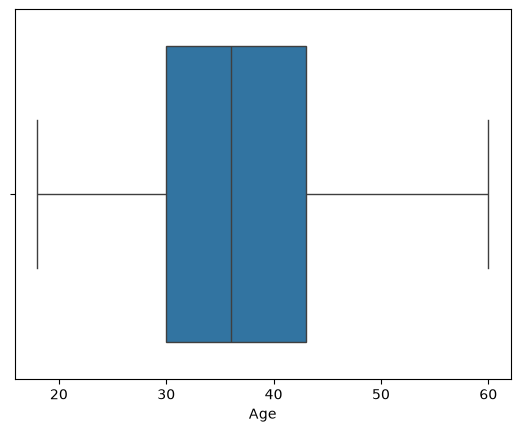

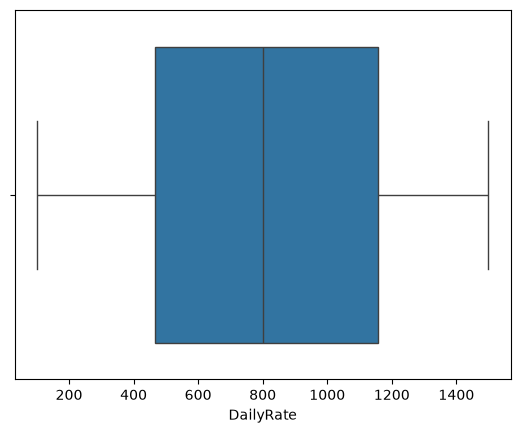

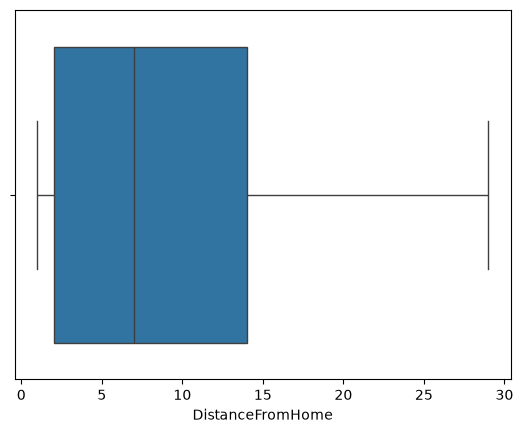

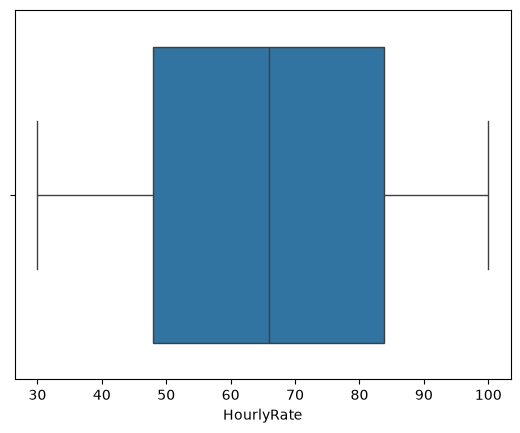

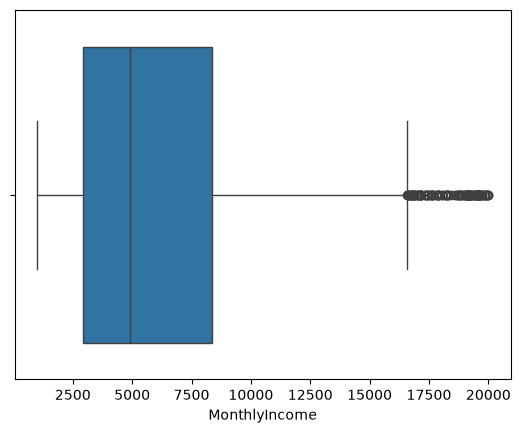

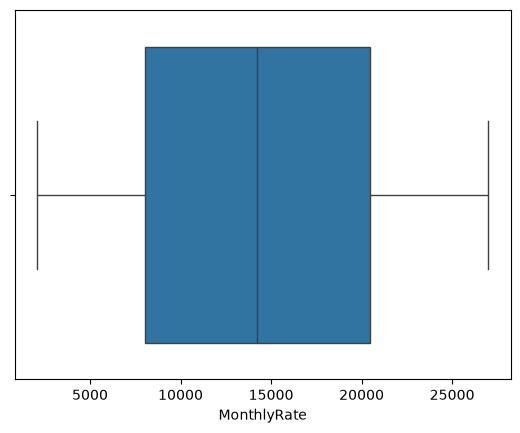

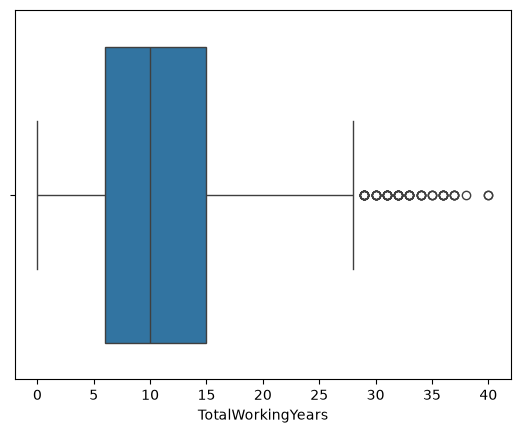

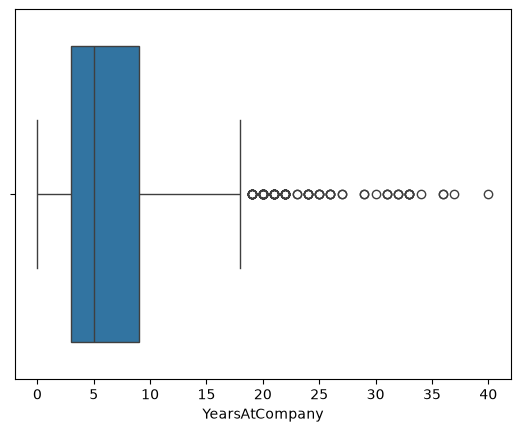

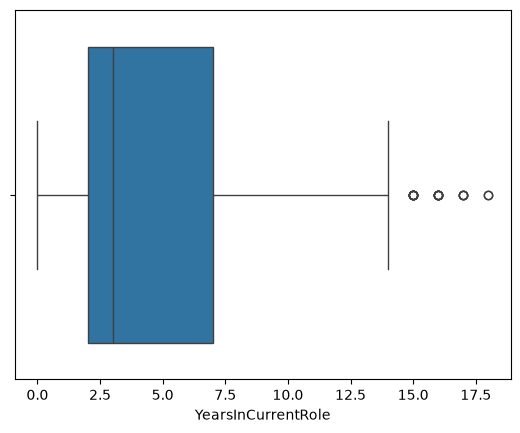

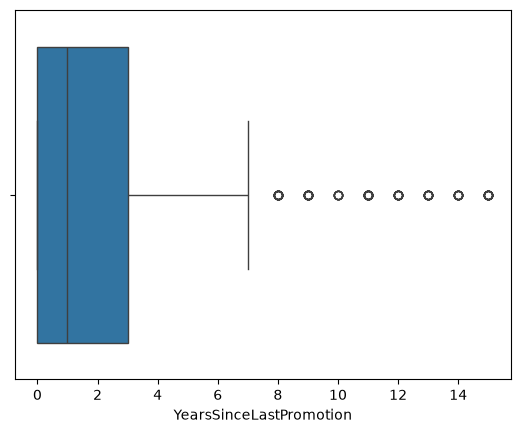

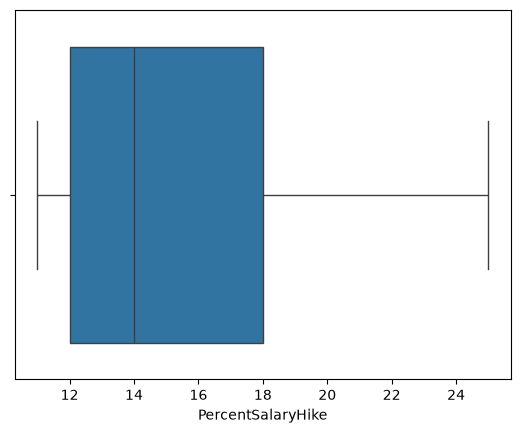

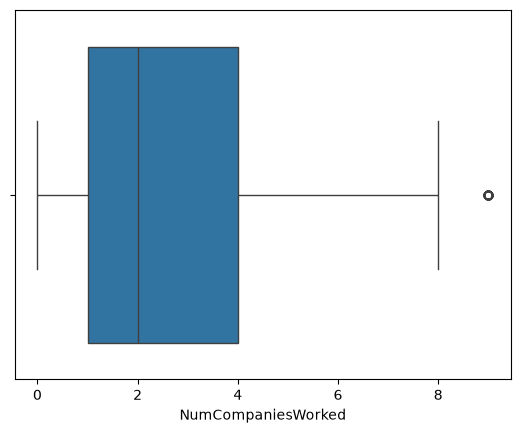

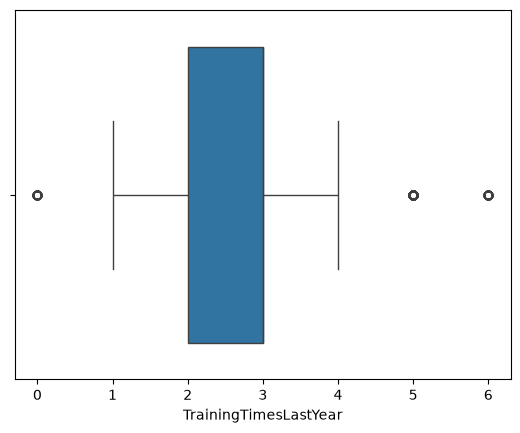

In [56]:
for i in genuine_cont_cols:
    sns.boxplot(data=emp_df,x=i)
    plt.show()

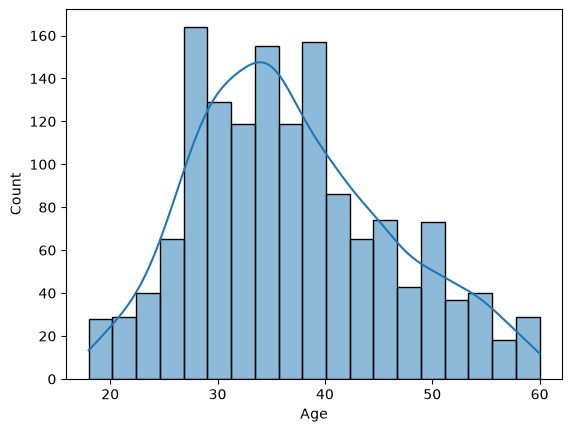

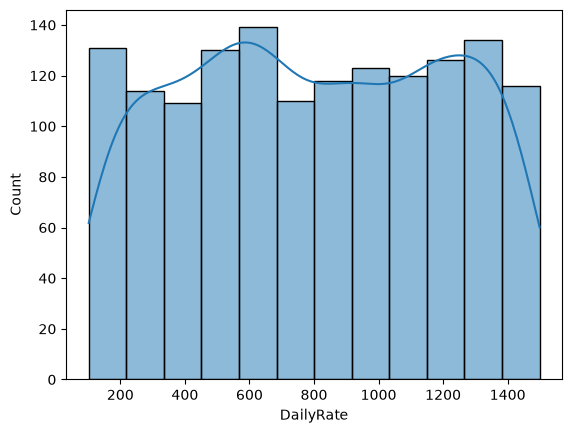

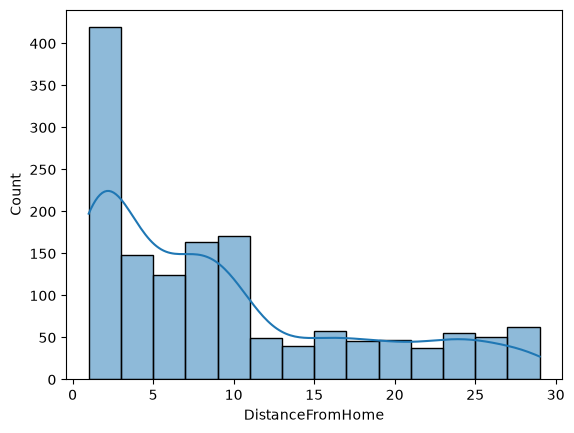

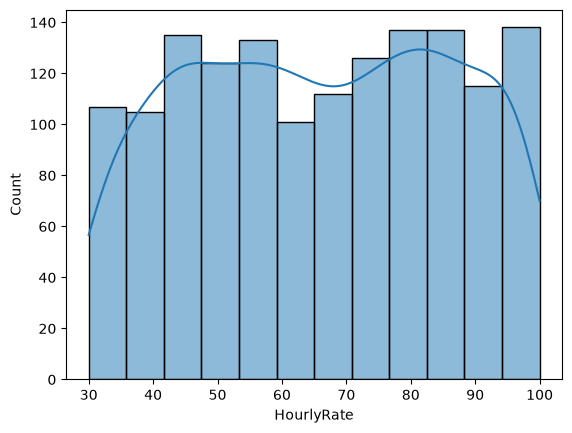

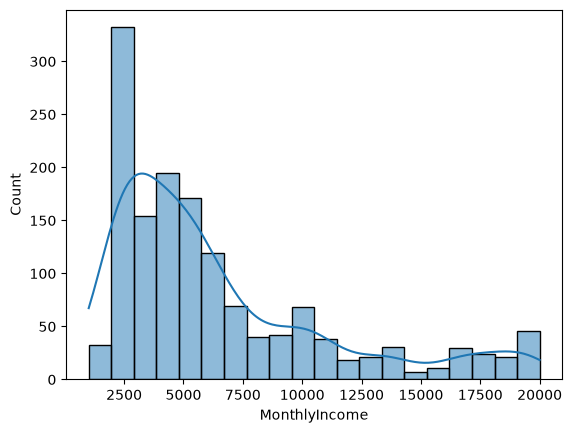

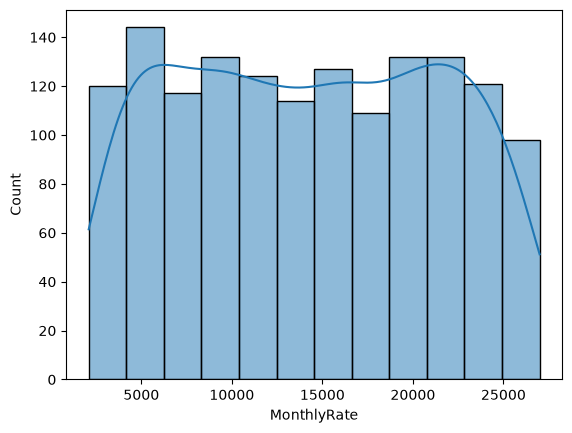

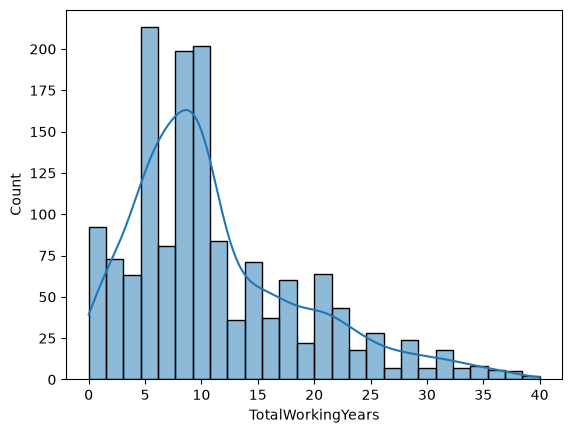

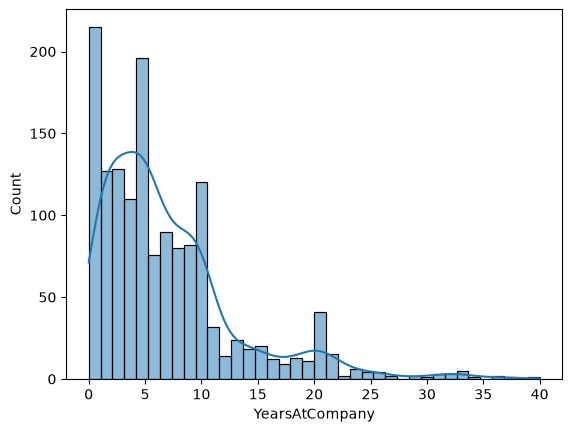

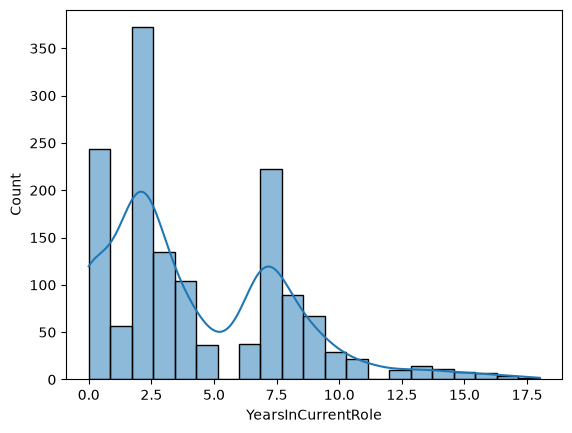

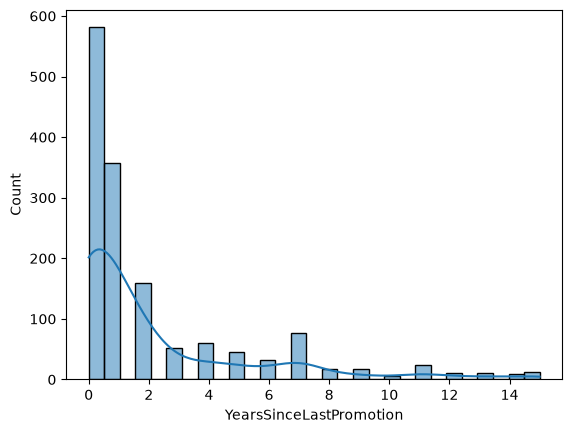

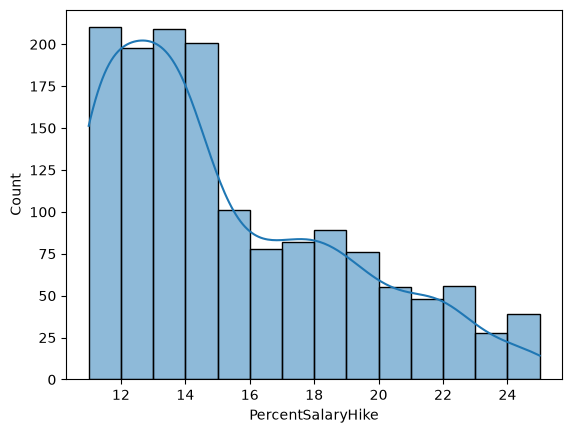

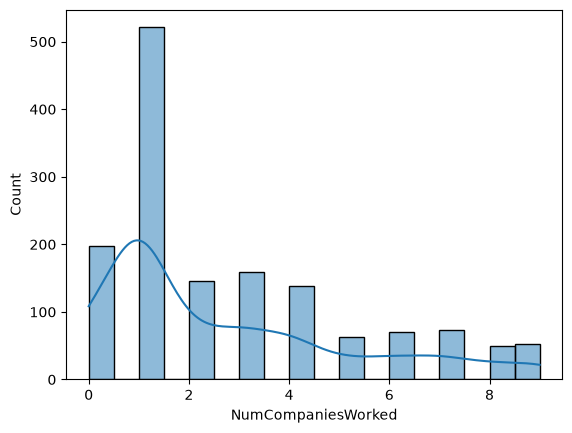

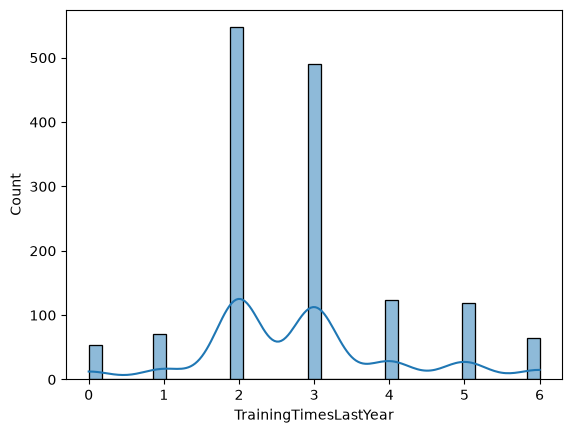

In [57]:
for i in genuine_cont_cols:
    sns.histplot(data=emp_df,x=i,kde=True)
    plt.show()

<Axes: xlabel='MonthlyRate', ylabel='Count'>

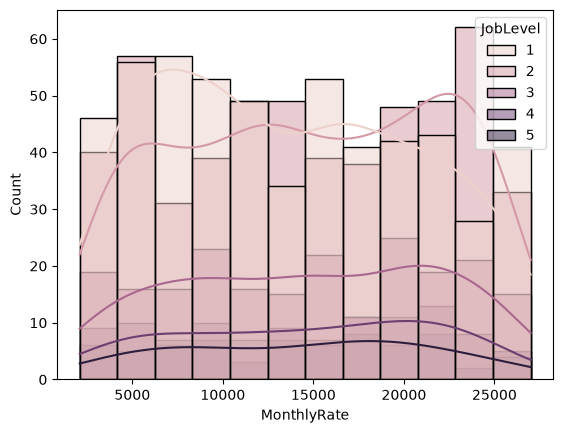

In [58]:
sns.histplot(data=emp_df, x='MonthlyRate', hue='JobLevel', kde=True)

<Axes: xlabel='DailyRate', ylabel='Count'>

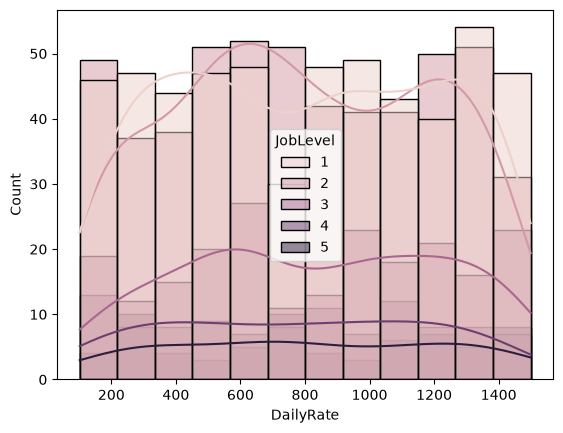

In [59]:
sns.histplot(data=emp_df, x='DailyRate', hue='JobLevel', kde=True)

<Axes: xlabel='HourlyRate', ylabel='Count'>

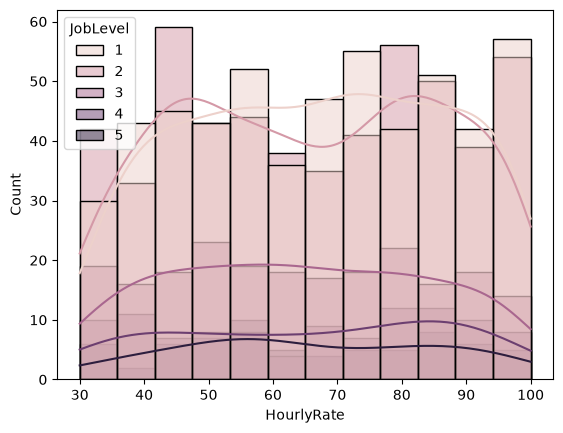

In [60]:
sns.histplot(data=emp_df, x='HourlyRate', hue='JobLevel', kde=True)

<Axes: xlabel='YearsInCurrentRole', ylabel='Count'>

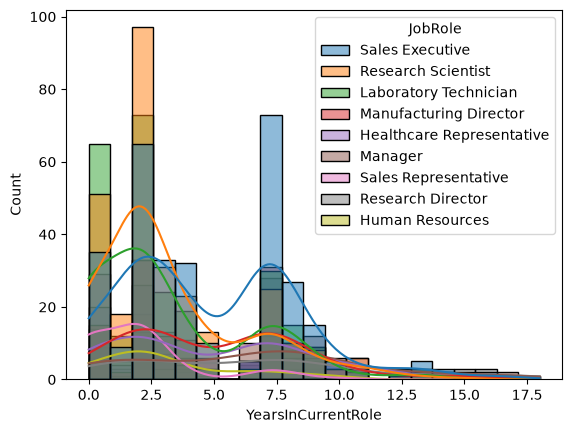

In [61]:
sns.histplot(data=emp_df, x='YearsInCurrentRole', hue='JobRole', kde=True)

<Axes: xlabel='TrainingTimesLastYear', ylabel='Count'>

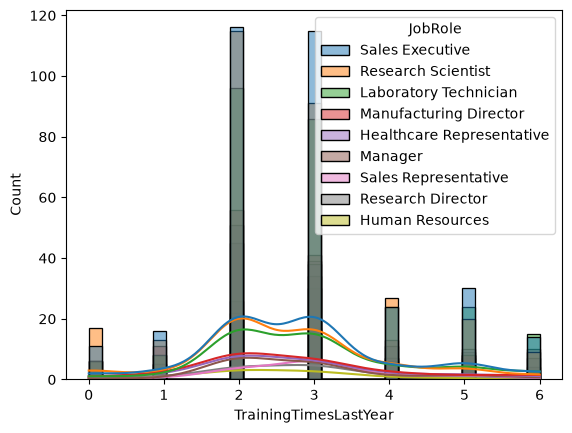

In [62]:
sns.histplot(data=emp_df, x='TrainingTimesLastYear', hue='JobRole', kde=True)

<Axes: xlabel='NumCompaniesWorked', ylabel='Count'>

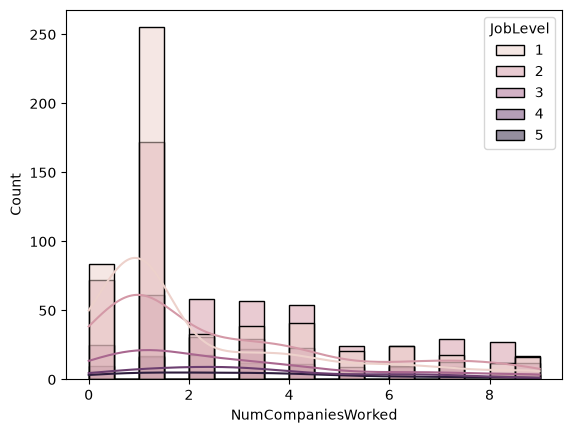

In [63]:
sns.histplot(data=emp_df, x='NumCompaniesWorked', hue='JobLevel', kde=True)

In [64]:
emp_df['JobLevel'].value_counts()

JobLevel
1    543
2    534
3    218
4    106
5     69
Name: count, dtype: int64

<Axes: xlabel='NumCompaniesWorked', ylabel='Count'>

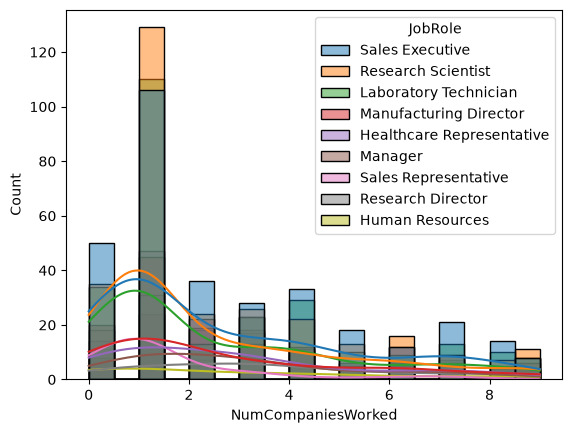

In [65]:
sns.histplot(data=emp_df, x='NumCompaniesWorked', hue='JobRole', kde=True)

In [66]:
# Univariate analysis

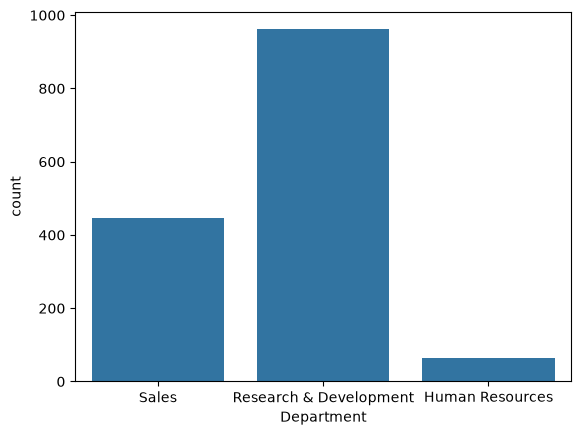

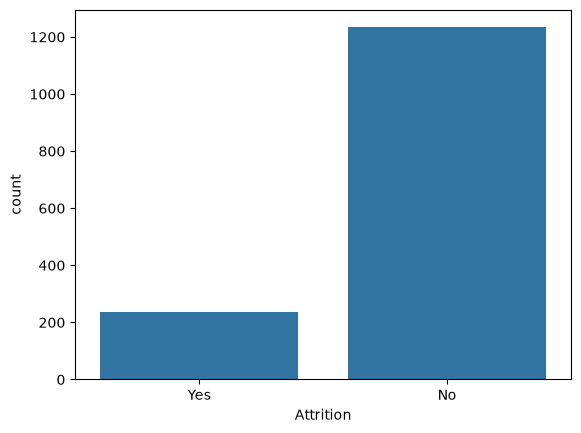

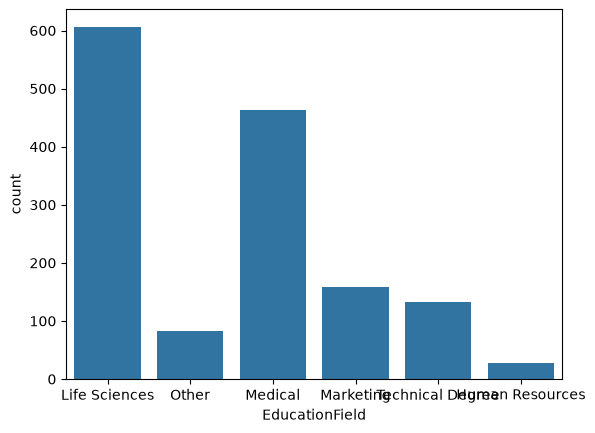

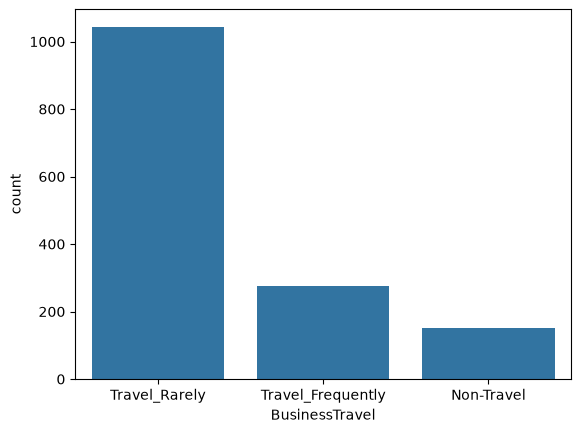

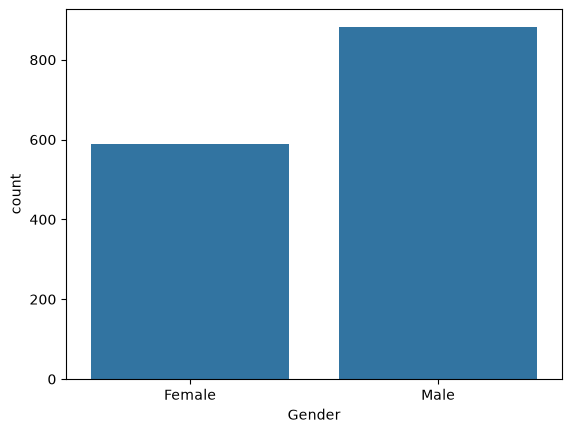

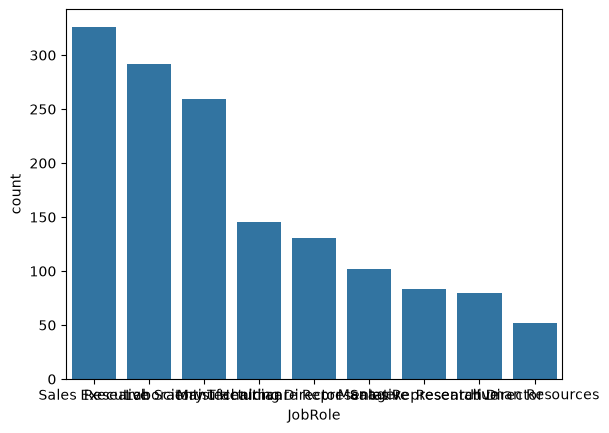

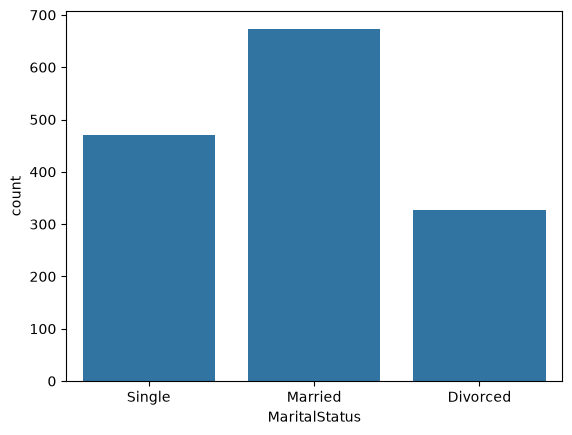

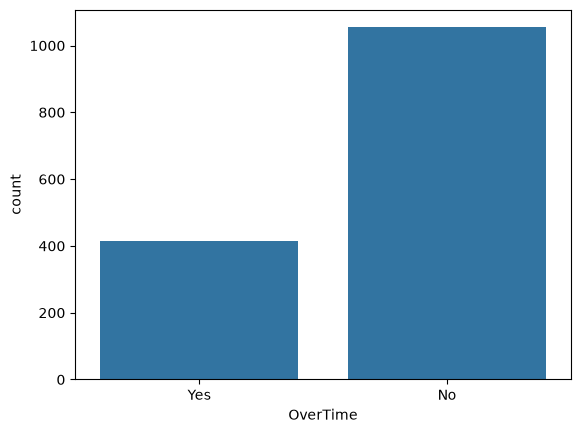

In [67]:
for i in cat_cols:
    sns.countplot(data=emp_df,x=i)
    plt.show()

# Bivariate Analysis

#### Overall attrition

In [68]:
attrition_pct = (emp_df['Attrition'].value_counts(normalize=True)*(100)).round(2).reset_index(name='Percentage')

In [69]:
attrition_pct

,Attrition,Percentage
0,No,83.88
1,Yes,16.12


#### Findings- 83.91% of employees were retained, while 16.09% experienced attrition.

### Gender wise attrition 

In [70]:
genderpct_df = emp_df.groupby('Gender')['Attrition'].value_counts(normalize=True).mul(100).reset_index(name='Percentage')

In [71]:
genderpct_df

,Gender,Attrition,Percentage
0,Female,No,85.204082
1,Female,Yes,14.795918
2,Male,No,82.993197
3,Male,Yes,17.006803


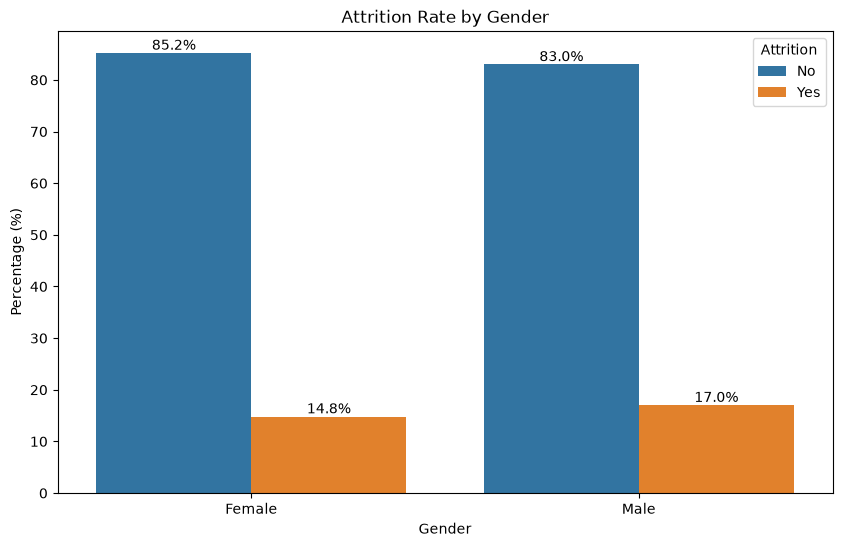

In [72]:
plt.figure(figsize=(10,6))
ax = sns.barplot(data=genderpct_df, x='Gender', y='Percentage', hue='Attrition')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%')

plt.title('Attrition Rate by Gender')
plt.ylabel('Percentage (%)')
plt.xlabel('Gender')
plt.show()

#### Findings- Among females 14.7% experienced attrition and among males this share is around 17%

### Age wise Attrition

In [73]:
agepct_df=(emp_df.groupby('AgeGroup')['Attrition'].value_counts(normalize=True)*100).round(2).reset_index(name='Percentage')

In [74]:
agepct_df

,AgeGroup,Attrition,Percentage
0,18-25,No,64.23
1,18-25,Yes,35.77
2,26-35,No,80.86
3,26-35,Yes,19.14
4,36-45,No,90.81
5,36-45,Yes,9.19
6,46-55,No,88.50
7,46-55,Yes,11.50
8,55+,No,82.98
9,55+,Yes,17.02


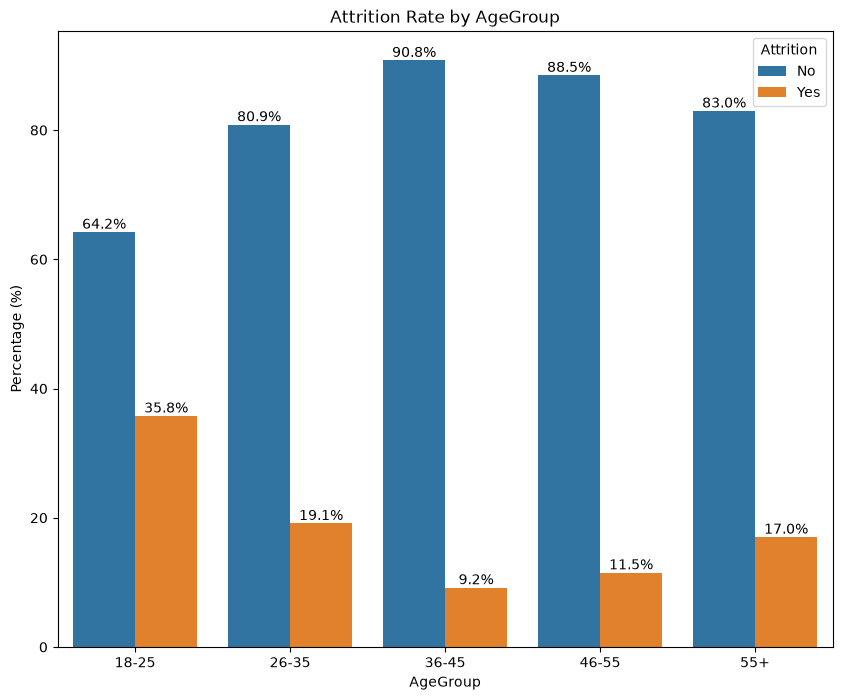

In [75]:
plt.figure(figsize=(10,8))
ax=sns.barplot(data=agepct_df,x='AgeGroup',y='Percentage',hue='Attrition')
for i in ax.containers:
    ax.bar_label(i,fmt='%.1f%%')
plt.title('Attrition Rate by AgeGroup')
plt.xlabel('AgeGroup')
plt.ylabel('Percentage (%)')
plt.show()

#### Findings-"18-25 age group shows the highest attrition rate, though the group is smaller than 26-35/36-45, showing yonnger employees are more likely to leave.

In [76]:
emp_df['AgeGroup'].value_counts()

AgeGroup
26-35    606
36-45    468
46-55    226
18-25    123
55+       47
Name: count, dtype: int64

### Department wise attrition

In [77]:
deptpct_df=(emp_df.groupby('Department')['Attrition'].value_counts(normalize=True)*100).round(2).reset_index(name='Percentage')

In [78]:
deptpct_df

,Department,Attrition,Percentage
0,Human Resources,No,80.95
1,Human Resources,Yes,19.05
2,Research & Development,No,86.16
3,Research & Development,Yes,13.84
4,Sales,No,79.37
5,Sales,Yes,20.63


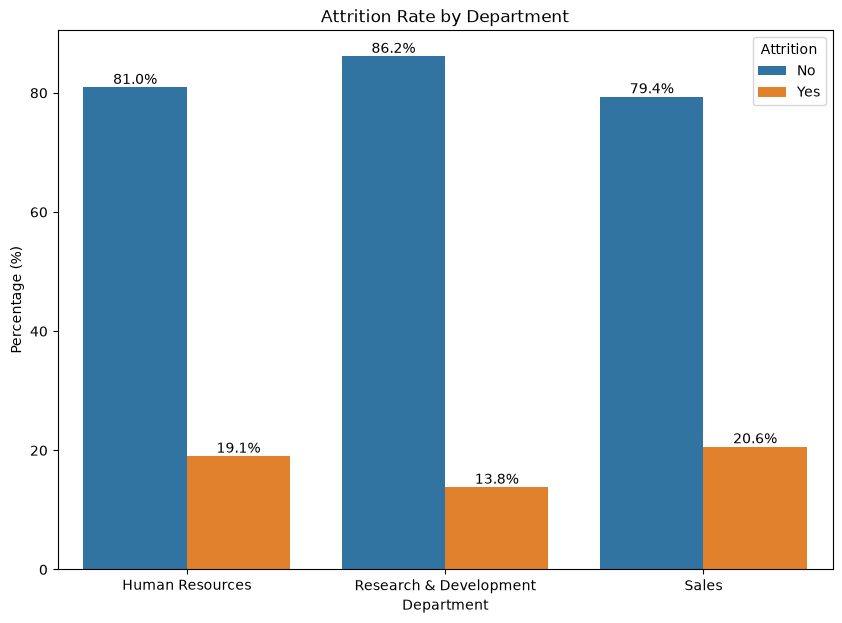

In [79]:
plt.figure(figsize=(10,7))
ax=sns.barplot(data=deptpct_df,x='Department',y='Percentage',hue='Attrition')
for i in ax.containers:
    ax.bar_label(i,fmt='%0.1f%%')
plt.title('Attrition Rate by Department')
plt.xlabel('Department')
plt.ylabel('Percentage (%)')
plt.show()

#### Findings- The attrition rates for Sales and Human Resources are relatively similar, with Sales at 20.5% and HR at 19%, a difference of 1.5 percentage points. However, since the Sales department has approximately 7 times more employees than HR, the higher attrition rate in Sales translates into a significantly larger number of employees leaving the organization.

In [80]:
emp_df['Department'].value_counts()

Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

### JobRole wise attrition

In [81]:
jobrolepct_df=(emp_df.groupby('JobRole')['Attrition'].value_counts(normalize=True)*100).round(2).reset_index(name='Percentage')

In [82]:
jobrolepct_df

,JobRole,Attrition,Percentage
0,Healthcare Representative,No,93.13
1,Healthcare Representative,Yes,6.87
2,Human Resources,No,76.92
3,Human Resources,Yes,23.08
4,Laboratory Technician,No,76.06
5,Laboratory Technician,Yes,23.94
6,Manager,No,95.10
7,Manager,Yes,4.90
8,Manufacturing Director,No,93.10
9,Manufacturing Director,Yes,6.90


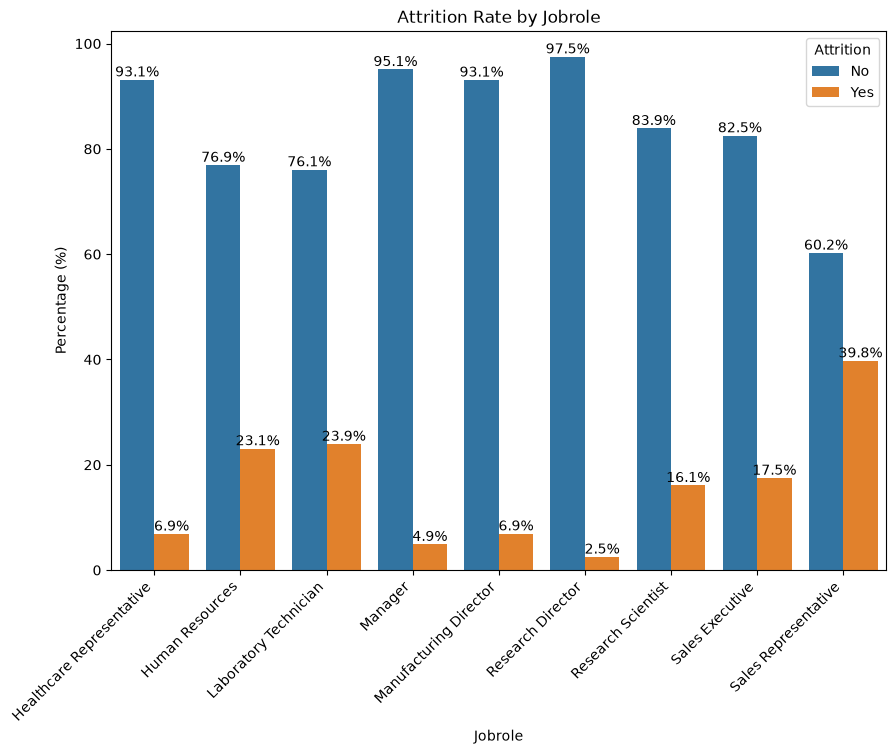

In [83]:
plt.figure(figsize=(10,7))
ax=sns.barplot(data=jobrolepct_df,x='JobRole',y='Percentage',hue='Attrition')
for i in ax.containers:
    ax.bar_label(i,fmt='%0.1f%%')

plt.xticks(rotation=45, ha='right')
plt.title('Attrition Rate by Jobrole')
plt.xlabel('Jobrole')
plt.ylabel('Percentage (%)')
plt.show()

#### Findings-Sales Representative shows the highest attrition rate (39.3%), though this is based on a smaller group (84 employees) compared to department-level figures, so it should be read as a strong signal rather than a definitive one."

In [84]:
emp_df['JobRole'].value_counts()

JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Name: count, dtype: int64

### Income wise attrition rate

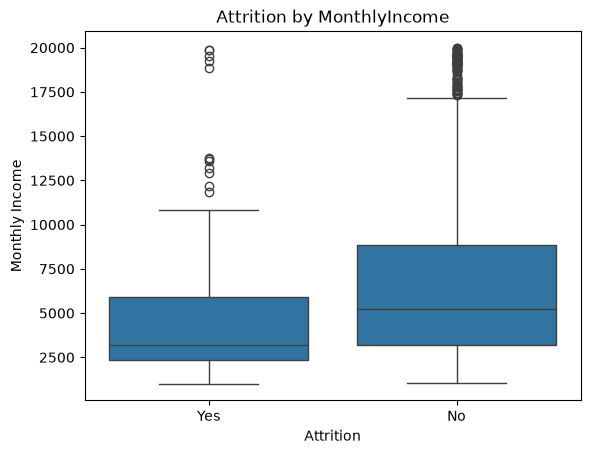

In [85]:
ax = sns.boxplot(
    data=emp_df,
    x='Attrition',
    y='MonthlyIncome'
)
plt.title('Attrition by MonthlyIncome')
plt.xlabel('Attrition')
plt.ylabel('Monthly Income')

plt.show()

#### Employees with a median salary of around ₹3,200 or below show a higher attrition rate compared with employees earning a median salary of approximately ₹5,200, suggesting that lower salary levels may be associated with higher employee attrition.


### Overtime wise attrition

In [86]:
overpct_df=(emp_df.groupby('OverTime')['Attrition'].value_counts(normalize=True)*100).round(2).reset_index(name='Percentage')

In [87]:
overpct_df

,OverTime,Attrition,Percentage
0,No,No,89.56
1,No,Yes,10.44
2,Yes,No,69.47
3,Yes,Yes,30.53


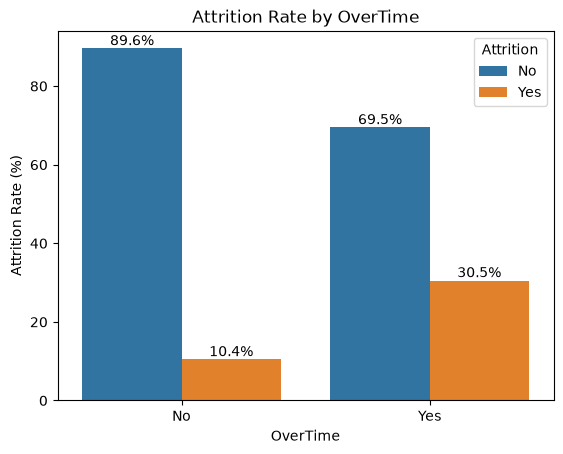

In [88]:
ax = sns.barplot(
    data=overpct_df,
    x='OverTime',
    y='Percentage',
    hue='Attrition'
)

for i in ax.containers:
    ax.bar_label(i, fmt='%0.1f%%')

plt.title('Attrition Rate by OverTime')
plt.xlabel('OverTime')
plt.ylabel('Attrition Rate (%)')

plt.show()
    

#### Findings-"employees working overtime are 3x more likely to leave."Employees who work overtime show a higher attrition rate (30.5%) compared with those who do not (10.4%), suggesting a possible association between overtime work and employee attrition. This relationship may also be influenced by other factors such as low salary which could might result in overtime.


In [89]:
emp_df['OverTime'].value_counts()

OverTime
No     1054
Yes     416
Name: count, dtype: int64

###  low salaried , overtime empployee attrition 

In [90]:
median_income=emp_df['MonthlyIncome'].median()

In [91]:
low_salaried_emp=emp_df[emp_df['MonthlyIncome']<median_income]

In [92]:
(low_salaried_emp.groupby('OverTime')['Attrition'].value_counts(normalize=True)*100).round(2).reset_index(name='Percentage')

,OverTime,Attrition,Percentage
0,No,No,86.30
1,No,Yes,13.70
2,Yes,No,56.93
3,Yes,Yes,43.07


#### Findings-"Low-salaried employees who also work overtime show 43% attrition — nearly 3x the overall rate — suggesting the combination of low pay and overwork is a critical retention risk."

### late promotion and low salaried attrition

In [93]:
low_salaried_emp['PromotionYearsBin'] = pd.cut(
    low_salaried_emp['YearsSinceLastPromotion'],
    bins=[-1, 2, 5, 8, 11, 15],
    labels=[
    '0–2 years',
    '3–5 years',
    '6–8 years',
    '9–11 years',
    '12+ years'
]
)

In [94]:
latepromoatt=(low_salaried_emp.groupby('PromotionYearsBin')['Attrition'].value_counts(normalize=True)*100).round(2).reset_index(name='Percentage')

In [95]:
latepromoatt.sort_values(['Attrition','Percentage'],ascending=False)

,PromotionYearsBin,Attrition,Percentage
9,12+ years,Yes,33.33
7,9–11 years,Yes,30.00
1,0–2 years,Yes,22.73
5,6–8 years,Yes,19.51
3,3–5 years,Yes,9.62
2,3–5 years,No,90.38
4,6–8 years,No,80.49
0,0–2 years,No,77.27
6,9–11 years,No,70.00
8,12+ years,No,66.67


In [96]:
low_salaried_emp['PromotionYearsBin'].value_counts()

PromotionYearsBin
0–2 years     629
3–5 years      52
6–8 years      41
9–11 years     10
12+ years       3
Name: count, dtype: int64

#### Findings-Among low-salaried employees, promotion wait alone doesn't clearly drive attrition — sample sizes in higher year bins are too small to draw conclusions. The 0–2 year group (n=630) shows 22.7% attrition, suggesting other factors matter more than promotion wait for this group."

In [97]:
emp_df.to_csv('HR_Analytics_cleaned.csv', index=False)
print('Exported successfully')
print('Final shape:', emp_df.shape)

Exported successfully
Final shape: (1470, 35)
